# **Springboard Decision Tree Specialty Coffee Case Study - Tier 3**




# The Scenario

Imagine you've just finished the Springboard Data Science Career Track course, and have been hired by a rising popular specialty coffee company - RR Diner Coffee - as a data scientist. Congratulations!

RR Diner Coffee sells two types of thing:
- specialty coffee beans, in bulk (by the kilogram only) 
- coffee equipment and merchandise (grinders, brewing equipment, mugs, books, t-shirts).

RR Diner Coffee has three stores, two in Europe and one in the USA. The flagshap store is in the USA, and everything is quality assessed there, before being shipped out. Customers further away from the USA flagship store have higher shipping charges. 

You've been taken on at RR Diner Coffee because the company are turning towards using data science and machine learning to systematically make decisions about which coffee farmers they should strike deals with. 

RR Diner Coffee typically buys coffee from farmers, processes it on site, brings it back to the USA, roasts it, packages it, markets it, and ships it (only in bulk, and after quality assurance) to customers internationally. These customers all own coffee shops in major cities like New York, Paris, London, Hong Kong, Tokyo, and Berlin. 

Now, RR Diner Coffee has a decision about whether to strike a deal with a legendary coffee farm (known as the **Hidden Farm**) in rural China: there are rumours their coffee tastes of lychee and dark chocolate, while also being as sweet as apple juice. 

It's a risky decision, as the deal will be expensive, and the coffee might not be bought by customers. The stakes are high: times are tough, stocks are low, farmers are reverting to old deals with the larger enterprises and the publicity of selling *Hidden Farm* coffee could save the RR Diner Coffee business. 

Your first job, then, is ***to build a decision tree to predict how many units of the Hidden Farm Chinese coffee will be purchased by RR Diner Coffee's most loyal customers.*** 

To this end, you and your team have conducted a survey of 710 of the most loyal RR Diner Coffee customers, collecting data on the customers':
- age
- gender 
- salary 
- whether they have bought at least one RR Diner Coffee product online
- their distance from the flagship store in the USA (standardized to a number between 0 and 11) 
- how much they spent on RR Diner Coffee products on the week of the survey 
- how much they spent on RR Diner Coffee products in the month preeding the survey
- the number of RR Diner coffee bean shipments each customer has ordered over the preceding year. 

You also asked each customer participating in the survey whether they would buy the Hidden Farm coffee, and some (but not all) of the customers gave responses to that question. 

You sit back and think: if more than 70% of the interviewed customers are likely to buy the Hidden Farm coffee, you will strike the deal with the local Hidden Farm farmers and sell the coffee. Otherwise, you won't strike the deal and the Hidden Farm coffee will remain in legends only. There's some doubt in your mind about whether 70% is a reasonable threshold, but it'll do for the moment. 

To solve the problem, then, you will build a decision tree to implement a classification solution. 


-------------------------------
As ever, this notebook is **tiered**, meaning you can elect that tier that is right for your confidence and skill level. There are 3 tiers, with tier 1 being the easiest and tier 3 being the hardest. This is ***tier 3***, so it will be challenging. 

**1. Sourcing and loading** 
- Import packages
- Load data
- Explore the data

 
**2. Cleaning, transforming and visualizing**
- Cleaning the data
- Train/test split
  
  
**3. Modelling** 
- Model 1: Entropy model - no max_depth
- Model 2: Gini impurity model - no max_depth
- Model 3: Entropy model - max depth 3
- Model 4: Gini impurity model - max depth 3


**4. Evaluating and concluding** 
- How many customers will buy Hidden Farm coffee?
- Decision

**5. Random Forest** 
- Import necessary modules
- Model
- Revise conclusion
    

# 0. Overview

This notebook uses decision trees to determine whether the factors of salary, gender, age, how much money the customer spent last week and during the preceding month on RR Diner Coffee products, how many kilogram coffee bags the customer bought over the last year, whether they have bought at least one RR Diner Coffee product online, and their distance from the flagship store in the USA, could predict whether customers would purchase the Hidden Farm coffee if a deal with its farmers were struck. 

# 1. Sourcing and loading
## 1a. Import Packages

In [1]:
# Data manipulation and numerical operations
import pandas as pd
import numpy as np

# Visualization
import seaborn as sns
import matplotlib.pyplot as plt

# Decision tree modeling and evaluation
from sklearn import tree, metrics
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# Tree visualization
from io import StringIO
from IPython.display import Image, display
import pydotplus

# Display plots directly in the notebook
%matplotlib inline

## 1b. Load data 

In [2]:
import pandas as pd
import os

file_path = os.path.expanduser(
    "~/Documents/GitHub/DataScienceTrack/CaseStudies/RRDinerCoffee/data/RRDinerCoffeeData.csv"
)

coffeeData = pd.read_csv(file_path)


## 1c. Explore the data

As we've seen, exploration entails doing things like checking out the **initial appearance** of the data with head(), the **dimensions** of our data with .shape, the **data types** of the variables with .info(), the **number of non-null values**, how much **memory** is being used to store the data, and finally the major summary statistcs capturing **central tendancy, dispersion and the null-excluding shape of the dataset's distribution**. 

How much of this can you do yourself by this point in the course? Have a real go. 

In [3]:
# Inspect the first five observations.
coffeeData.head(8)

,Age,Gender,num_coffeeBags_per_year,spent_week,spent_month,SlrAY,Distance,Online,Decision
0,36,Female,0,24,73,42789,0.003168,0,1.0
1,24,Male,0,44,164,74035,0.520906,0,NaN
2,24,Male,0,39,119,30563,0.916005,1,1.0
3,20,Male,0,30,107,13166,0.932098,1,NaN
4,24,Female,0,20,36,14244,0.965881,0,1.0
5,20,female,0,23,28,14293,1.036346,1,1.0
6,34,Female,0,55,202,91035,1.134851,0,1.0
7,24,Female,0,20,34,17425,1.193188,0,NaN


In [4]:
# Call .shape on your data
coffeeData.shape

(702, 9)

In [5]:
# Call info() on your data
coffeeData.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 702 entries, 0 to 701
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      702 non-null    int64  
 1   Gender                   702 non-null    object 
 2   num_coffeeBags_per_year  702 non-null    int64  
 3   spent_week               702 non-null    int64  
 4   spent_month              702 non-null    int64  
 5   SlrAY                    702 non-null    int64  
 6   Distance                 702 non-null    float64
 7   Online                   702 non-null    int64  
 8   Decision                 474 non-null    float64
dtypes: float64(2), int64(6), object(1)
memory usage: 49.5+ KB


In [6]:
# Call describe() on your data with include='all'
coffeeData.describe(include="all")

,Age,Gender,num_coffeeBags_per_year,spent_week,spent_month,SlrAY,Distance,Online,Decision
count,702.000000,702,702.000000,702.000000,702.000000,702.000000,702.000000,702.000000,474.000000
unique,NaN,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,Male,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,355,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,34.243590,NaN,2.710826,32.853276,107.923077,43819.843305,4.559186,0.531339,0.639241
std,13.927945,NaN,1.593629,15.731878,55.348485,26192.626943,3.116275,0.499373,0.480728
min,16.000000,NaN,0.000000,0.000000,0.000000,1617.000000,0.003168,0.000000,0.000000
25%,23.000000,NaN,1.000000,24.250000,62.000000,22812.250000,1.877812,0.000000,0.000000
50%,28.000000,NaN,3.000000,36.000000,113.500000,41975.000000,4.196167,1.000000,1.000000
75%,46.000000,NaN,4.000000,43.000000,150.750000,60223.000000,6.712022,1.000000,1.000000


# 2. Cleaning, transforming and visualizing
## 2a. Cleaning the data

Some datasets don't require any cleaning, but almost all do. This one does. We need to replace '1.0' and '0.0' in the 'Decision' column by 'YES' and 'NO' respectively, clean up the values of the 'gender' column, and change the column names to words which maximize meaning and clarity. 

First, let's change the name of `spent_week`, `spent_month`, and `SlrAY` to `spent_last_week` and `spent_last_month` and `salary` respectively.

In [7]:
# Check out the names of our data's columns 
coffeeData.columns

Index(['Age', 'Gender', 'num_coffeeBags_per_year', 'spent_week', 'spent_month',
       'SlrAY', 'Distance', 'Online', 'Decision'],
      dtype='object')

In [8]:
# Make the relevant name changes to spent_week and spent_per_week.
coffeeData.rename(
    columns={
        "spent_month": "spent_last_month",
        "spent_week": "spent_last_week",
        "SlrAY": "Salary"
    },
    inplace=True
)

# Check out the column names
coffeeData.columns

Index(['Age', 'Gender', 'num_coffeeBags_per_year', 'spent_last_week',
       'spent_last_month', 'Salary', 'Distance', 'Online', 'Decision'],
      dtype='object')

In [9]:
# Call describe() on the gender column
coffeeData["Gender"].describe()

count      702
unique       9
top       Male
freq       355
Name: Gender, dtype: object

In [10]:
# Call unique() on the gender column to see its unique values
coffeeData["Gender"].unique()

array(['Female', 'Male', 'female', 'F', 'f ', 'FEMALE', 'MALE', 'male',
       'M'], dtype=object)

In [11]:
# Replace alternate values with 'Female'
coffeeData["Gender"] = coffeeData["Gender"].replace(
    ["female", "f ", "FEMALE", "F"],
    "Female"
)

# Let's check the unique values of the column "Gender"
coffeeData["Gender"].unique()

array(['Female', 'Male', 'MALE', 'male', 'M'], dtype=object)

We can see a bunch of inconsistency here.

Use replace() to make the values of the `gender` column just `Female` and `Male`.

In [12]:
# Replace all alternate values with "Male"
# Replace alternate values with 'Male'
coffeeData["Gender"] = coffeeData["Gender"].replace(
    ["MALE", "male", "M"],
    "Male"
)

# Let's check the unique values of the column "Gender"
coffeeData["Gender"].unique()

array(['Female', 'Male'], dtype=object)

In [13]:
# Check out the unique values of the column 'Decision'
coffeeData["Decision"].unique()

array([ 1., nan,  0.])

In [14]:
# Replace 1.0 and 0.0 in the Decision column
coffeeData["Decision"] = coffeeData["Decision"].replace({
    1.0: "YES",
    0.0: "NO"
})

# Check that the replacement worked
coffeeData["Decision"].unique()

array(['YES', nan, 'NO'], dtype=object)

In [15]:
# Inspect the cleaned data types and non-null values
coffeeData.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 702 entries, 0 to 701
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      702 non-null    int64  
 1   Gender                   702 non-null    object 
 2   num_coffeeBags_per_year  702 non-null    int64  
 3   spent_last_week          702 non-null    int64  
 4   spent_last_month         702 non-null    int64  
 5   Salary                   702 non-null    int64  
 6   Distance                 702 non-null    float64
 7   Online                   702 non-null    int64  
 8   Decision                 474 non-null    object 
dtypes: float64(1), int64(6), object(2)
memory usage: 49.5+ KB



I standardized the gender values so that each gender category is represented consistently. I also renamed the spending and salary columns to make their meanings clearer and converted the numerical decision values into readable YES and NO labels. Missing decision responses remain missing because they will be predicted later.

## 2b. Train/test split
To execute the train/test split properly, we need to do five things: 
1. Drop all rows with a null value in the `Decision` column, and save the result as NOPrediction: a dataset that will contain all known values for the decision 
2. Visualize the data using scatter and boxplots of several variables in the y-axis and the decision on the x-axis
3. Get the subset of coffeeData with null values in the `Decision` column, and save that subset as Prediction
4. Divide the NOPrediction subset into X and y, and then further divide those subsets into train and test subsets for X and y respectively
5. Create dummy variables to deal with categorical inputs

### 1. Drop all null values within the `Decision` column, and save the result as NoPrediction

In [16]:
# NoPrediction will contain all known values for the decision
NOPrediction = coffeeData.dropna(subset=["Decision"])

# Describe the Decision column
NOPrediction["Decision"].describe()

count     474
unique      2
top       YES
freq      303
Name: Decision, dtype: object

### 2. Visualize the data using scatter and boxplots of several variables in the y-axis and the decision on the x-axis

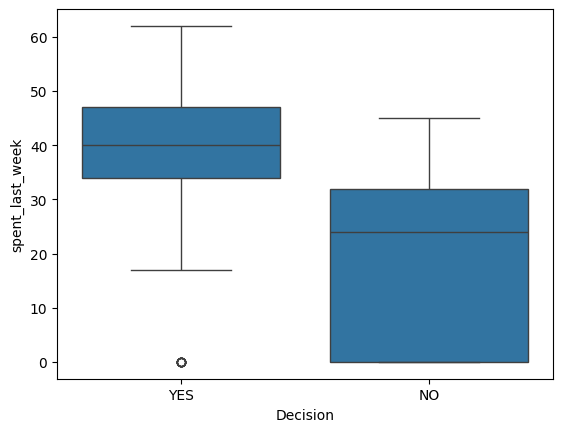

In [17]:
# Explore weekly spending by decision
sns.boxplot(
    y="spent_last_week",
    x="Decision",
    data=NOPrediction
)

plt.show()

Can you admissibly conclude anything from this boxplot? Write your answer here: The boxplot allows us to compare weekly spending between customers who said YES and those who said NO. Differences in the medians and distributions may suggest an association between weekly spending and purchase intention. However, the plot alone cannot establish causation or prove that weekly spending will accurately predict decisions for new customers.

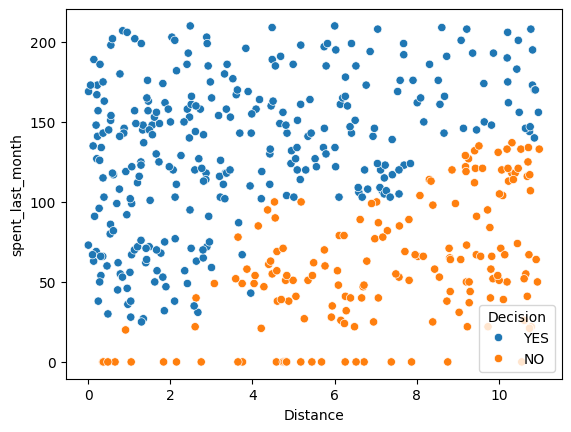

In [18]:
# Explore monthly spending by decision and distance
sns.scatterplot(
    y="spent_last_month",
    x="Distance",
    hue="Decision",
    data=NOPrediction
)

plt.show()

Can you admissibly conclude anything from this scatterplot? Remember: we are trying to build a tree to classify unseen examples. Write your answer here: The scatterplot helps us examine how monthly spending and distance vary across the two decision groups. Any visible patterns may be useful when selecting predictive features. However, the points may overlap substantially, and the plot alone does not tell us how accurately a decision tree will classify unseen customers. We need to evaluate the model using a separate test set.

### 3. Get the subset of coffeeData with null values in the Decision column, and save that subset as Prediction

In [19]:
# Get just those rows whose value for the Decision column is null  
Prediction = coffeeData[pd.isnull(coffeeData["Decision"])]

# Check the first rows
Prediction.head()

,Age,Gender,num_coffeeBags_per_year,spent_last_week,spent_last_month,Salary,Distance,Online,Decision
1,24,Male,0,44,164,74035,0.520906,0,NaN
3,20,Male,0,30,107,13166,0.932098,1,NaN
7,24,Female,0,20,34,17425,1.193188,0,NaN
11,24,Female,0,40,153,84803,1.655096,1,NaN
12,21,Female,0,38,122,42338,1.714179,1,NaN


In [20]:
# Call describe() on Prediction
Prediction.describe()

,Age,num_coffeeBags_per_year,spent_last_week,spent_last_month,Salary,Distance,Online
count,228.000000,228.000000,228.000000,228.000000,228.000000,228.000000,228.000000
mean,31.802632,2.960526,33.394737,110.407895,41923.741228,3.428836,0.570175
std,14.302293,1.585514,15.697930,53.786536,27406.768360,2.153102,0.496140
min,16.000000,0.000000,0.000000,0.000000,1617.000000,0.010048,0.000000
25%,22.000000,2.000000,25.750000,65.000000,15911.500000,1.699408,0.000000
50%,25.000000,3.000000,37.000000,113.500000,40987.500000,3.208673,1.000000
75%,39.000000,4.000000,44.000000,151.250000,58537.000000,5.261184,1.000000
max,67.000000,5.000000,62.000000,210.000000,182058.000000,10.871566,1.000000


### 4. Divide the NOPrediction subset into X and y

In [21]:
# Check the names of the columns of NOPrediction
NOPrediction.columns

Index(['Age', 'Gender', 'num_coffeeBags_per_year', 'spent_last_week',
       'spent_last_month', 'Salary', 'Distance', 'Online', 'Decision'],
      dtype='object')

In [22]:
# Select the explanatory features
features = [
    "Age",
    "Gender",
    "num_coffeeBags_per_year",
    "spent_last_week",
    "spent_last_month",
    "Salary",
    "Distance",
    "Online"
]

# Create explanatory variables
X = NOPrediction[features]

# Create the target variable
y = NOPrediction.Decision

### 5. Create dummy variables to deal with categorical inputs
One-hot encoding replaces each unique value of a given column with a new column, and puts a 1 in the new column for a given row just if its initial value for the original column matches the new column. Check out [this resource](https://hackernoon.com/what-is-one-hot-encoding-why-and-when-do-you-have-to-use-it-e3c6186d008f) if you haven't seen one-hot-encoding before. 

**Note**: We will do this before we do our train/test split as to do it after could mean that some categories only end up in the train or test split of our data by chance and this would then lead to different shapes of data for our `X_train` and `X_test` which could/would cause downstream issues when fitting or predicting using a trained model.

In [23]:
# One-hot encode all features in X
X = pd.get_dummies(X)

### 6. Further divide those subsets into train and test subsets for X and y respectively: X_train, X_test, y_train, y_test

In [24]:
# Call train_test_split on X, y. Make the test_size = 0.25, and random_state = 246
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=246
)

# 3. Modelling
It's useful to look at the scikit-learn documentation on decision trees https://scikit-learn.org/stable/modules/tree.html before launching into applying them. If you haven't seen them before, take a look at that link, in particular the section `1.10.5.` 

## Model 1: Entropy model - no max_depth

We'll give you a little more guidance here, as the Python is hard to deduce, and scikitlearn takes some getting used to.

Theoretically, let's remind ourselves of what's going on with a decision tree implementing an entropy model.

Ross Quinlan's **ID3 Algorithm** was one of the first, and one of the most basic, to use entropy as a metric.

**Entropy** is a measure of how uncertain we are about which category the data-points fall into at a given point in the tree. The **Information gain** of a specific feature with a threshold (such as 'spent_last_month <= 138.0') is the difference in entropy that exists before and after splitting on that feature; i.e., the information we gain about the categories of the data-points by splitting on that feature and that threshold. 

Naturally, we want to minimize entropy and maximize information gain. Quinlan's ID3 algorithm is designed to output a tree such that the features at each node, starting from the root, and going all the way down to the leaves, have maximial information gain. We want a tree whose leaves have elements that are *homogeneous*, that is, all of the same category. 

The first model will be the hardest. Persevere and you'll reap the rewards: you can use almost exactly the same code for the other models. 

In [25]:
# Declare a variable called entr_model and use tree.DecisionTreeClassifier. 
entr_model = tree.DecisionTreeClassifier(
    criterion="entropy",
    random_state=1234
)

# Call fit() on entr_model
entr_model.fit(X_train, y_train)

# Call predict() on entr_model with X_test passed to it, and assign the result to a variable y_pred 
y_pred = entr_model.predict(X_test)

# Call Series on our y_pred variable with the following: pd.Series(y_pred)
y_pred = pd.Series(y_pred)

# Check out entr_model
entr_model

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",1234
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsam

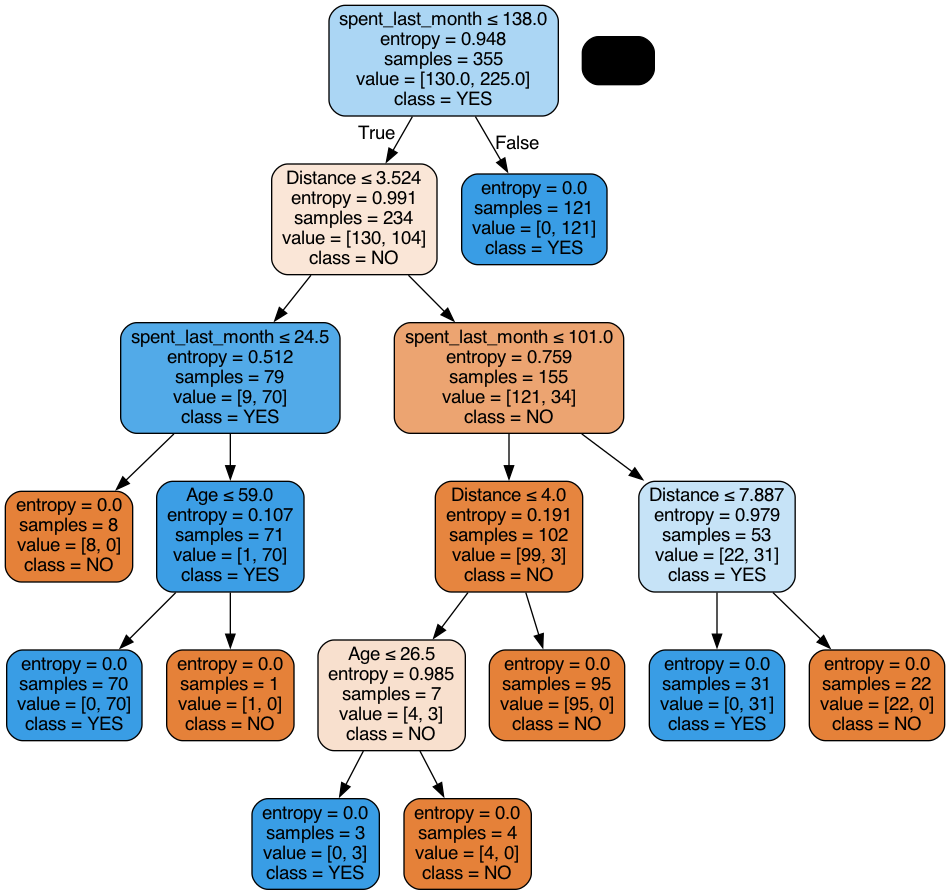

In [26]:
# Now we want to visualize the tree
dot_data = StringIO()

# We can do so with export_graphviz
tree.export_graphviz(
    entr_model,
    out_file=dot_data,
    filled=True,
    rounded=True,
    special_characters=True,
    feature_names=X_train.columns,
    class_names=["NO", "YES"]
)

graph = pydotplus.graph_from_dot_data(dot_data.getvalue())
Image(graph.create_png())

## Model 1: Entropy model - no max_depth: Interpretation and evaluation

In [27]:
# Run this block for model evaluation metrics 
print("Model Entropy - no max depth")
print("Accuracy:", metrics.accuracy_score(y_test,y_pred))
print("Balanced accuracy:", metrics.balanced_accuracy_score(y_test,y_pred))
print('Precision score for "Yes"' , metrics.precision_score(y_test,y_pred, pos_label = "YES"))
print('Precision score for "No"' , metrics.precision_score(y_test,y_pred, pos_label = "NO"))
print('Recall score for "Yes"' , metrics.recall_score(y_test,y_pred, pos_label = "YES"))
print('Recall score for "No"' , metrics.recall_score(y_test,y_pred, pos_label = "NO"))

Model Entropy - no max depth
Accuracy: 0.9915966386554622
Balanced accuracy: 0.9878048780487805
Precision score for "Yes" 0.9873417721518988
Precision score for "No" 1.0
Recall score for "Yes" 1.0
Recall score for "No" 0.975609756097561


What can you infer from these results? Write your conclusions here:

The unrestricted entropy tree can learn complex patterns in the training data, but it may also overfit by creating many branches that capture noise or specific examples. Test accuracy and the precision and recall scores help us evaluate its predictive performance. We should not assume that a complex tree is the best model simply because it fits the training data well.

Use the actual metric values printed by your notebook to determine whether its test performance is satisfactory.

## Model 2: Gini impurity model - no max_depth

Gini impurity, like entropy, is a measure of how well a given feature (and threshold) splits the data into categories.

Their equations are similar, but Gini impurity doesn't require logorathmic functions, which can be computationally expensive. 

In [28]:
# Make a variable called gini_model, and assign it exactly what you assigned entr_model with above, but with the
# criterion changed to 'gini'
gini_model = tree.DecisionTreeClassifier(
    criterion="gini",
    random_state=1234
)

# Call fit() on the gini_model as you did with the entr_model
gini_model.fit(X_train, y_train)

# Call predict() on the gini_model as you did with the entr_model 
y_pred = gini_model.predict(X_test)

# Turn y_pred into a series, as before
y_pred = pd.Series(y_pred)

# Check out gini_model
gini_model

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",1234
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

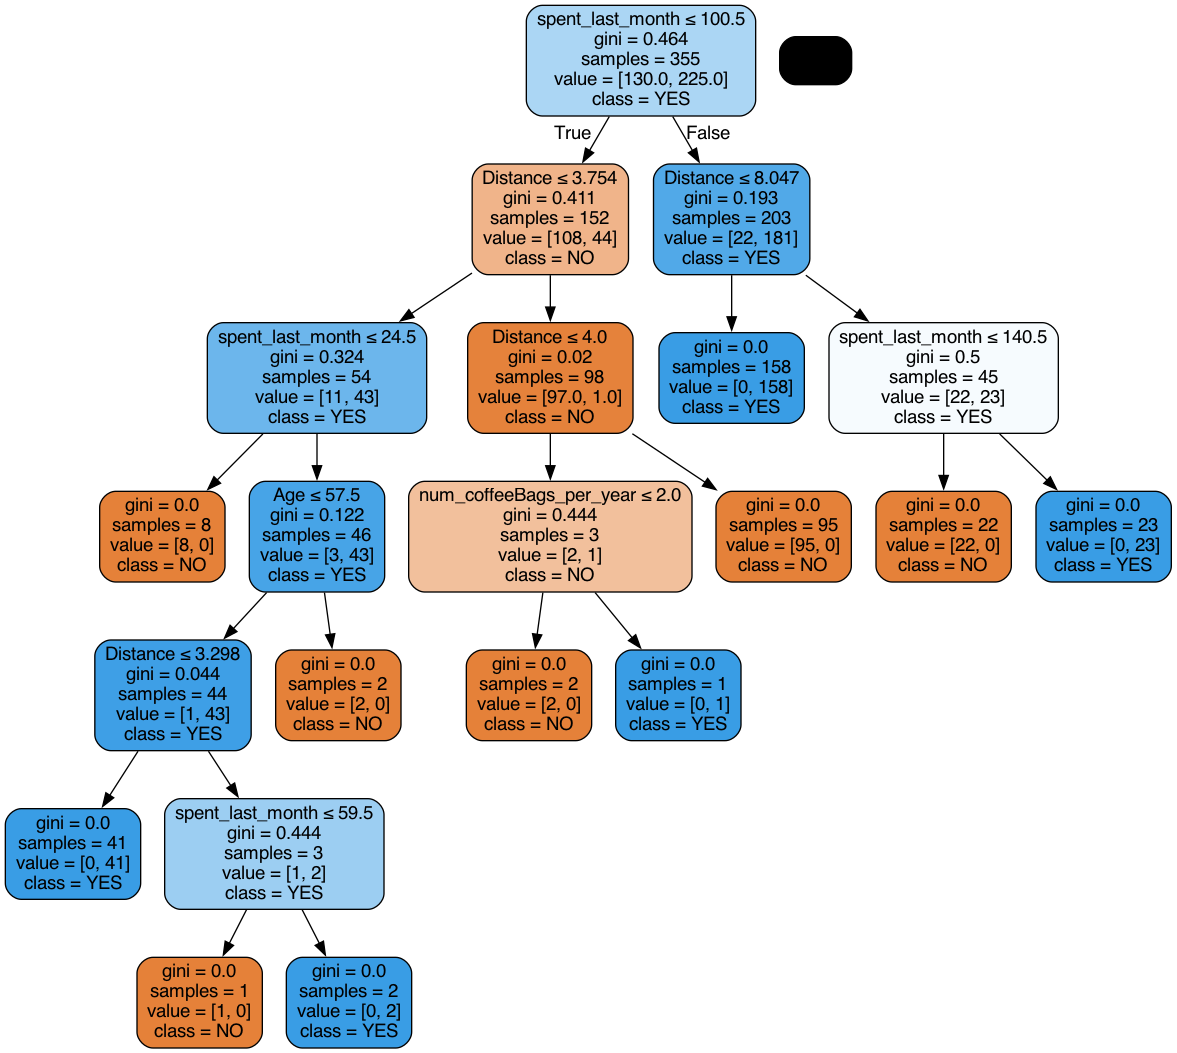

In [29]:
# As before, but make the model name gini_model
dot_data = StringIO()

tree.export_graphviz(
    gini_model,
    out_file=dot_data,
    feature_names=X.columns,
    class_names=gini_model.classes_,
    filled=True,
    rounded=True,
    special_characters=True
)

# Alternatively for class_names use gini_model.classes_
graph = pydotplus.graph_from_dot_data(dot_data.getvalue())
display(Image(graph.create_png()))

In [30]:
# Evaluate Model 2
print("Model Gini impurity - no max depth")
print("Accuracy:", metrics.accuracy_score(y_test, y_pred))
print("Balanced accuracy:", metrics.balanced_accuracy_score(y_test, y_pred))
print(
    'Precision score for "YES"',
    metrics.precision_score(y_test, y_pred, pos_label="YES", zero_division=0)
)
print(
    'Precision score for "NO"',
    metrics.precision_score(y_test, y_pred, pos_label="NO", zero_division=0)
)
print(
    'Recall score for "YES"',
    metrics.recall_score(y_test, y_pred, pos_label="YES", zero_division=0)
)
print(
    'Recall score for "NO"',
    metrics.recall_score(y_test, y_pred, pos_label="NO", zero_division=0)
)

Model Gini impurity - no max depth
Accuracy: 0.9831932773109243
Balanced accuracy: 0.9813946216385241
Precision score for "YES" 0.9871794871794872
Precision score for "NO" 0.975609756097561
Recall score for "YES" 0.9871794871794872
Recall score for "NO" 0.975609756097561


How do the results here compare to the previous model? Write your judgements here: 
The entropy and Gini models use different criteria to measure the quality of a split. Their performance may be similar or different depending on the dataset. I would compare their test accuracy, balanced accuracy, precision, and recall to determine which performs better. Neither criterion is guaranteed to produce the best model in every situation.

## Model 3: Entropy model - max depth 3
We're going to try to limit the depth of our decision tree, using entropy first.  

As you know, we need to strike a balance with tree depth. 

Insufficiently deep, and we're not giving the tree the opportunity to spot the right patterns in the training data.

Excessively deep, and we're probably going to make a tree that overfits to the training data, at the cost of very high error on the (hitherto unseen) test data. 

Sophisticated data scientists use methods like random search with cross-validation to systematically find a good depth for their tree. We'll start with picking 3, and see how that goes. 

In [31]:
# Create an entropy tree with a maximum depth of 3
entr_model2 = tree.DecisionTreeClassifier(
    criterion="entropy",
    max_depth=3,
    random_state=1234
)

# Fit, predict, and convert predictions to a Series
entr_model2.fit(X_train, y_train)
y_pred = entr_model2.predict(X_test)
y_pred = pd.Series(y_pred)

# Check the model
entr_model2

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",1234
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

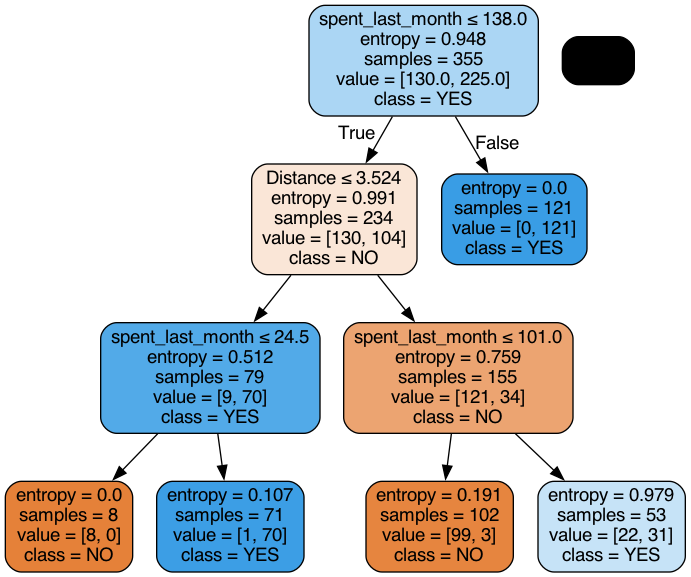

In [32]:
# Visualize the depth-limited tree
dot_data = StringIO()

tree.export_graphviz(
    entr_model2,
    out_file=dot_data,
    filled=True,
    rounded=True,
    special_characters=True,
    feature_names=X_train.columns,
    class_names=["NO", "YES"]
)

graph = pydotplus.graph_from_dot_data(dot_data.getvalue())
Image(graph.create_png())


In [33]:
# Evaluate Model 3
print("Model Entropy - max depth 3")
print("Accuracy:", metrics.accuracy_score(y_test, y_pred))
print("Balanced accuracy:", metrics.balanced_accuracy_score(y_test, y_pred))
print(
    'Precision score for "YES"',
    metrics.precision_score(y_test, y_pred, pos_label="YES", zero_division=0)
)
print(
    'Recall score for "YES"',
    metrics.recall_score(y_test, y_pred, pos_label="YES", zero_division=0)
)
print(
    'Precision score for "NO"',
    metrics.precision_score(y_test, y_pred, pos_label="NO", zero_division=0)
)
print(
    'Recall score for "NO"',
    metrics.recall_score(y_test, y_pred, pos_label="NO", zero_division=0)
)

Model Entropy - max depth 3
Accuracy: 0.907563025210084
Balanced accuracy: 0.8658536585365854
Precision score for "YES" 0.8764044943820225
Recall score for "YES" 1.0
Precision score for "NO" 1.0
Recall score for "NO" 0.7317073170731707


So our accuracy decreased, but is this certainly an inferior tree to the max depth original tree we did with Model 1? Write your conclusions here: 
No. A decrease in test accuracy does not automatically mean that the depth-limited tree is inferior. Restricting the tree to a depth of three reduces complexity and may reduce overfitting. A simpler tree can be easier to explain to business stakeholders and may generalize better to new customers. We should compare its test metrics and performance stability before deciding which model is preferable.

## Model 4: Gini impurity  model - max depth 3
We're now going to try the same with the Gini impurity model. 

In [34]:
# Create a Gini tree with a maximum depth of 3
gini_model2 = tree.DecisionTreeClassifier(
    criterion="gini",
    random_state=1234,
    max_depth=3
)

# Fit, predict, and convert predictions to a Series
gini_model2.fit(X_train, y_train)
y_pred = gini_model2.predict(X_test)
y_pred = pd.Series(y_pred)

# Check the model
gini_model2

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",1234
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples a

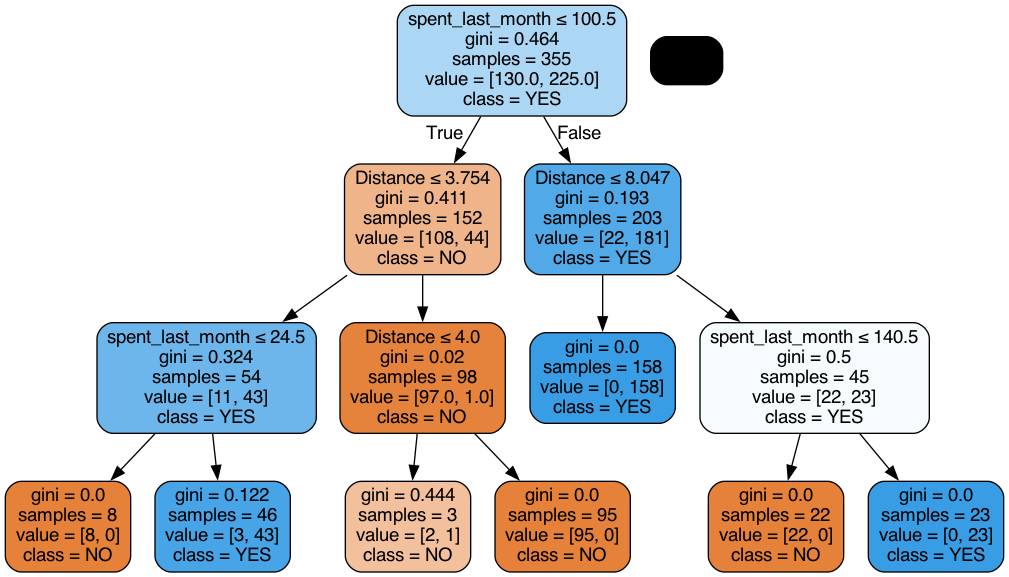

In [35]:
# Visualize the depth-limited Gini tree
dot_data = StringIO()

tree.export_graphviz(
    gini_model2,
    out_file=dot_data,
    filled=True,
    rounded=True,
    special_characters=True,
    feature_names=X_train.columns,
    class_names=["NO", "YES"]
)

graph = pydotplus.graph_from_dot_data(dot_data.getvalue())
Image(graph.create_png())

In [36]:
# Evaluate Model 4
print("Gini impurity - max depth 3")
print("Accuracy:", metrics.accuracy_score(y_test, y_pred))
print("Balanced accuracy:", metrics.balanced_accuracy_score(y_test, y_pred))
print(
    'Precision score for "YES"',
    metrics.precision_score(y_test, y_pred, pos_label="YES", zero_division=0)
)
print(
    'Recall score for "YES"',
    metrics.recall_score(y_test, y_pred, pos_label="YES", zero_division=0)
)
print(
    'Precision score for "NO"',
    metrics.precision_score(y_test, y_pred, pos_label="NO", zero_division=0)
)
print(
    'Recall score for "NO"',
    metrics.recall_score(y_test, y_pred, pos_label="NO", zero_division=0)
)

Gini impurity - max depth 3
Accuracy: 0.9747899159663865
Balanced accuracy: 0.9691994996873046
Precision score for "YES" 0.9746835443037974
Recall score for "YES" 0.9871794871794872
Precision score for "NO" 0.975
Recall score for "NO" 0.9512195121951219


Now this is an elegant tree. Its accuracy might not be the highest, but it's still the best model we've produced so far. Why is that? Write your answer here: 
The depth-limited Gini tree is simpler to interpret and explain than an unrestricted tree. Its limited depth can help control overfitting, while still identifying useful patterns in customer behavior. If its test performance is reasonably strong, its balance between predictive performance and interpretability can make it a practical choice for business decision-making. However, we should confirm this using the actual evaluation results rather than assuming that it is automatically the best model.

# 4. Evaluating and concluding
## 4a. How many customers will buy Hidden Farm coffee? 
Let's first ascertain how many loyal customers claimed, in the survey, that they will purchase the Hidden Farm coffee. 

In [37]:
# Call value_counts() on the 'Decision' column of the original coffeeData
coffeeData["Decision"].value_counts()

Decision
YES    303
NO     171
Name: count, dtype: int64

Let's now determine the number of people that, according to the model, will be willing to buy the Hidden Farm coffee. 
1. First we subset the Prediction dataset into `new_X` considering all the variables except `Decision` 
2. Use that dataset to predict a new variable called `potential_buyers`

In [38]:
# Select the features for prediction
feature_cols = [
    "Age",
    "Gender",
    "num_coffeeBags_per_year",
    "spent_last_week",
    "spent_last_month",
    "Salary",
    "Distance",
    "Online"
]

# Select the explanatory variables from Prediction
new_X = Prediction[feature_cols]

# One-hot encode categorical features
new_X = pd.get_dummies(new_X)

# Match the prediction columns to the training columns
new_X = new_X.reindex(columns=X_train.columns, fill_value=0)

# Predict the decisions using the depth-limited Gini model
potential_buyers = gini_model2.predict(new_X)

# Count the predicted YES and NO responses
prediction_counts = pd.Series(potential_buyers).value_counts()

print(prediction_counts)

# Calculate the percentage of customers predicted to buy
predicted_yes = (potential_buyers == "YES").sum()
total_predictions = len(potential_buyers)

print("Predicted YES:", predicted_yes)
print("Total predictions:", total_predictions)
print(
    "Percentage predicted to buy:",
    round((predicted_yes / total_predictions) * 100, 2),
    "%"
)

YES    183
NO      45
Name: count, dtype: int64
Predicted YES: 183
Total predictions: 228
Percentage predicted to buy: 80.26 %


In [39]:
# Count known YES responses
known_yes = (NOPrediction["Decision"] == "YES").sum()

# Estimate total buyers among all surveyed customers
estimated_yes = known_yes + predicted_yes
total_surveyed = len(coffeeData)

print("Known YES responses:", known_yes)
print("Predicted YES responses:", predicted_yes)
print("Estimated total buyers:", estimated_yes)
print("Total surveyed:", total_surveyed)
print(
    "Estimated purchase rate:",
    round((estimated_yes / total_surveyed) * 100, 2),
    "%"
)

Known YES responses: 303
Predicted YES responses: 183
Estimated total buyers: 486
Total surveyed: 702
Estimated purchase rate: 69.23 %


The total number of potential buyers is 303 + 183 = 486

In [40]:
# Print the total number of surveyed people with a non-null salary
print("The total number of surveyed people was", coffeeData.Salary.count())

The total number of surveyed people was 702


In [41]:
# Calculate the proportion of predicted buyers
486 / 702

0.6923076923076923

In [42]:
# Print the predicted percentage of buyers
print(
    "Only",
    round((486 / 702) * 100, 2),
    "% of people are predicted to want to buy the Hidden Farm coffee."
)

Only 69.23 % of people are predicted to want to buy the Hidden Farm coffee.


## 4b. Decision
Remember how you thought at the start: if more than 70% of the interviewed customers are likely to buy the Hidden Farm coffee, you will strike the deal with the local Hidden Farm farmers and sell the coffee. Otherwise, you won't strike the deal and the Hidden Farm coffee will remain in legends only. Well now's crunch time. Are you going to go ahead with that idea? If so, you won't be striking the deal with the Chinese farmers. 

They're called `decision trees`, aren't they? So where's the decision? What should you do? (Cue existential cat emoji). 

Ultimately, though, we can't write an algorithm to actually *make the business decision* for us. This is because such decisions depend on our values, what risks we are willing to take, the stakes of our decisions, and how important it us for us to *know* that we will succeed. What are you going to do with the models you've made? Are you going to risk everything, strike the deal with the *Hidden Farm* farmers, and sell the coffee? 

The philosopher of language Jason Stanley once wrote that the number of doubts our evidence has to rule out in order for us to know a given proposition depends on our stakes: the higher our stakes, the more doubts our evidence has to rule out, and therefore the harder it is for us to know things. We can end up paralyzed in predicaments; sometimes, we can act to better our situation only if we already know certain things, which we can only if our stakes were lower and we'd *already* bettered our situation. 

Data science and machine learning can't solve such problems. But what it can do is help us make great use of our data to help *inform* our decisions.

Based on the model's predictions, approximately 69.23% of the surveyed customers with non-null salary values are estimated to want to buy Hidden Farm coffee. This is below the company's initial threshold of 70%, so I would not recommend immediately committing to the deal based on this result alone.

However, the difference is small, and the model's predictions are uncertain. I would recommend gathering additional customer feedback, validating the model's performance, and assessing the financial risks and potential benefits of the partnership before making a final decision. The decision tree provides useful evidence, but the ultimate business decision also depends on the cost of the deal, expected revenue, and the company's tolerance for risk.

## 5. Random Forest
You might have noticed an important fact about decision trees. Each time we run a given decision tree algorithm to make a prediction (such as whether customers will buy the Hidden Farm coffee) we will actually get a slightly different result. This might seem weird, but it has a simple explanation: machine learning algorithms are by definition ***stochastic***, in that their output is at least partly determined by randomness. 

To account for this variability and ensure that we get the most accurate prediction, we might want to actually make lots of decision trees, and get a value that captures the centre or average of the outputs of those trees. Luckily, there's a method for this, known as the ***Random Forest***. 

Essentially, Random Forest involves making lots of trees with similar properties, and then performing summary statistics on the outputs of those trees to reach that central value. Random forests are hugely powerful classifers, and they can improve predictive accuracy and control over-fitting. 

Why not try to inform your decision with random forest? You'll need to make use of the RandomForestClassifier function within the sklearn.ensemble module, found [here](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html). 

### 5a. Import necessary modules

In [43]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import make_classification

### 5b. Model
You'll use your X_train and y_train variables just as before.

You'll then need to make a variable (call it firstRFModel) to store your new Random Forest model. You'll assign this variable the result of calling RandomForestClassifier().

Then, just as before, you'll call fit() on that firstRFModel variable, and plug in X_train and y_train.

Finally, you should make a variable called y_pred, and assign it the result of calling the predict() method on your new firstRFModel, with the X_test data passed to it. 

In [44]:
# Create a random forest classifier
firstRFModel = RandomForestClassifier(
    max_depth=3,
    random_state=1234
)

# Fit the model
firstRFModel.fit(X_train, y_train)

# Predict decisions for the test set
y_pred = firstRFModel.predict(X_test)



In [45]:
# Evaluate the random forest
print("Random Forest - max depth 3")
print("Accuracy:", metrics.accuracy_score(y_test, y_pred))
print("Balanced accuracy:", metrics.balanced_accuracy_score(y_test, y_pred))
print(
    'Precision score for "YES"',
    metrics.precision_score(y_test, y_pred, pos_label="YES", zero_division=0)
)
print(
    'Recall score for "YES"',
    metrics.recall_score(y_test, y_pred, pos_label="YES", zero_division=0)
)
print(
    'Precision score for "NO"',
    metrics.precision_score(y_test, y_pred, pos_label="NO", zero_division=0)
)
print(
    'Recall score for "NO"',
    metrics.recall_score(y_test, y_pred, pos_label="NO", zero_division=0)
)

Random Forest - max depth 3
Accuracy: 0.9411764705882353
Balanced accuracy: 0.9204190118824265
Precision score for "YES" 0.927710843373494
Recall score for "YES" 0.9871794871794872
Precision score for "NO" 0.9722222222222222
Recall score for "NO" 0.8536585365853658


In [46]:
# Predict decisions for customers with missing responses
rf_potential_buyers = firstRFModel.predict(new_X)

# Count predicted YES and NO responses
rf_prediction_counts = pd.Series(rf_potential_buyers).value_counts()
print(rf_prediction_counts)

# Calculate the percentage predicted to buy
rf_predicted_yes = (rf_potential_buyers == "YES").sum()
rf_total_predictions = len(rf_potential_buyers)

print("Predicted YES:", rf_predicted_yes)
print("Total predictions:", rf_total_predictions)
print(
    "Percentage predicted to buy:",
    round((rf_predicted_yes / rf_total_predictions) * 100, 2),
    "%"
)

YES    189
NO      39
Name: count, dtype: int64
Predicted YES: 189
Total predictions: 228
Percentage predicted to buy: 82.89 %


### 5c. Revise conclusion

The Random Forest predicted that 189 out of 228 customers with missing survey responses would want to buy Hidden Farm coffee, representing 82.89%. This is higher than the 80.26% predicted by the depth-limited Gini decision tree for the same group of customers.

Random Forest combines multiple decision trees, which can help improve prediction stability and reduce overfitting. However, the model's test-set accuracy, balanced accuracy, precision, and recall should be compared with those of the single decision tree to determine which model performs better.

When the 189 predicted YES responses are combined with the 303 customers who originally answered YES, the estimated total is 492 potential buyers. Among the 702 customers with non-null salary values, this represents approximately 70.09%, which is slightly above the company's initial threshold of 70%. Therefore, the Random Forest estimate changes the initial recommendation compared with the single decision tree, which estimated a purchase rate of 69.23%.

However, the difference is small, and the predictions for customers with missing responses are estimates rather than confirmed purchase intentions. Before committing to the deal, I would recommend validating the model's performance, gathering additional customer feedback, and assessing the expected costs, potential revenue, and financial risks of the partnership.